# Predicting Heart Attack Chance

## Pakcages & Libs

In [142]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [123]:
import warnings
warnings.filterwarnings('ignore')

### Reading Data

#### **Chance Of Heart Attack (Output)**: 
- 0: low Chance
- 1: High Chance

In [124]:
df = pd.read_csv("16325569497737558.csv")
df.head()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [125]:
df.describe()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


## Pre-processing

In [126]:
X = np.asarray(df[["age", "sex", "cp", "trtbps", "chol", "fbs", "restecg", "thalachh", "exng", "caa"]])
X[:5]

array([[ 63,   1,   3, 145, 233,   1,   0, 150,   0,   0],
       [ 37,   1,   2, 130, 250,   0,   1, 187,   0,   0],
       [ 41,   0,   1, 130, 204,   0,   0, 172,   0,   0],
       [ 56,   1,   1, 120, 236,   0,   1, 178,   0,   0],
       [ 57,   0,   0, 120, 354,   0,   1, 163,   1,   0]], dtype=int64)

In [127]:
y = np.asarray(df[["output"]])
y[:5]

array([[1],
       [1],
       [1],
       [1],
       [1]], dtype=int64)

Normilizing X values for Logistic Regression

In [128]:
X_LR = preprocessing.StandardScaler().fit(X).transform(X)
X_LR[0:5]

array([[ 0.9521966 ,  0.68100522,  1.97312292,  0.76395577, -0.25633371,
         2.394438  , -1.00583187,  0.01544279, -0.69663055, -0.71442887],
       [-1.91531289,  0.68100522,  1.00257707, -0.09273778,  0.07219949,
        -0.41763453,  0.89896224,  1.63347147, -0.69663055, -0.71442887],
       [-1.47415758, -1.46841752,  0.03203122, -0.09273778, -0.81677269,
        -0.41763453, -1.00583187,  0.97751389, -0.69663055, -0.71442887],
       [ 0.18017482,  0.68100522,  0.03203122, -0.66386682, -0.19835726,
        -0.41763453,  0.89896224,  1.23989692, -0.69663055, -0.71442887],
       [ 0.29046364, -1.46841752, -0.93851463, -0.66386682,  2.08204965,
        -0.41763453,  0.89896224,  0.58393935,  1.43548113, -0.71442887]])

## Creating Train & Test  

Train & Test for Decision Tree Modeling

In [129]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)
x_train[:5]

array([[ 60,   1,   0, 140, 293,   0,   0, 170,   0,   2],
       [ 69,   1,   3, 160, 234,   1,   0, 131,   0,   1],
       [ 54,   1,   0, 140, 239,   0,   1, 160,   0,   0],
       [ 66,   0,   2, 146, 278,   0,   0, 152,   0,   1],
       [ 59,   1,   1, 140, 221,   0,   1, 164,   1,   0]], dtype=int64)

In [130]:
x_test[:5]

array([[ 53,   1,   2, 130, 246,   1,   0, 173,   0,   3],
       [ 63,   0,   0, 124, 197,   0,   1, 136,   1,   0],
       [ 58,   0,   0, 100, 248,   0,   0, 122,   0,   0],
       [ 41,   0,   1, 105, 198,   0,   1, 168,   0,   1],
       [ 70,   1,   0, 130, 322,   0,   0, 109,   0,   3]], dtype=int64)

Train & Test for Logistic Regression Modeling

In [131]:
x_train_, x_test_, y_train_, y_test_ = train_test_split(X_LR, y, test_size=0.2, random_state=2)
x_train_[:5]

array([[ 0.62133012,  0.68100522, -0.93851463,  0.47839125,  0.90319523,
        -0.41763453, -1.00583187,  0.89005288, -0.69663055,  1.24459328],
       [ 1.61392956,  0.68100522,  1.97312292,  1.62064933, -0.23700823,
         2.394438  , -1.00583187, -0.81543681, -0.69663055,  0.26508221],
       [-0.04040284,  0.68100522, -0.93851463,  0.47839125, -0.14038081,
        -0.41763453,  0.89896224,  0.45274783, -0.69663055, -0.71442887],
       [ 1.28306308, -1.46841752,  1.00257707,  0.82106867,  0.613313  ,
        -0.41763453, -1.00583187,  0.1029038 , -0.69663055,  0.26508221],
       [ 0.5110413 ,  0.68100522,  0.03203122,  0.47839125, -0.4882395 ,
        -0.41763453,  0.89896224,  0.62766985,  1.43548113, -0.71442887]])

## Decision Tree Modeling

Criterion: gini

In [132]:
gini_tree = DecisionTreeClassifier(criterion="gini")
gini_tree

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


Criterion: entropy

In [133]:
entropy_tree = DecisionTreeClassifier(criterion="entropy")
entropy_tree

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


Criterion: log_loss

In [134]:
log_loss_tree = DecisionTreeClassifier(criterion="log_loss")
log_loss_tree

,criterion,'log_loss'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [135]:
gini_tree.fit(x_train, y_train)
entropy_tree.fit(x_train, y_train)
log_loss_tree.fit(x_train, y_train)

,criterion,'log_loss'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


## Decision Tree Evaluation

In [136]:
y_pred_gini = gini_tree.predict(x_test)
y_pred_entropy = entropy_tree.predict(x_test)
y_pred_log_loss = log_loss_tree.predict(x_test)

print(classification_report(y_test, y_pred_gini))
print(classification_report(y_test, y_pred_entropy))
print(classification_report(y_test, y_pred_log_loss))

              precision    recall  f1-score   support

           0       0.89      0.78      0.83        32
           1       0.79      0.90      0.84        29

    accuracy                           0.84        61
   macro avg       0.84      0.84      0.84        61
weighted avg       0.84      0.84      0.84        61

              precision    recall  f1-score   support

           0       0.85      0.72      0.78        32
           1       0.74      0.86      0.79        29

    accuracy                           0.79        61
   macro avg       0.79      0.79      0.79        61
weighted avg       0.80      0.79      0.79        61

              precision    recall  f1-score   support

           0       0.88      0.72      0.79        32
           1       0.74      0.90      0.81        29

    accuracy                           0.80        61
   macro avg       0.81      0.81      0.80        61
weighted avg       0.82      0.80      0.80        61



In conclusion, Decision Tree with gini criterion has better accuracy.

## Logistic Regression Modeling
### Logistic Regression Evaluation
c = 0.01 ... 0.09

In [137]:
c_range = np.arange(0.01, 0.1, 0.01)

for c in c_range:
    LR = LogisticRegression(C=c, solver="liblinear")
    LR.fit(x_train_, y_train_)

    y_hat = LR.predict(x_test_)
    acc = accuracy_score(y_test_, y_hat)
    print(f"C: {c}, Accuracy: {acc}")

C: 0.01, Accuracy: 0.8852459016393442
C: 0.02, Accuracy: 0.8852459016393442
C: 0.03, Accuracy: 0.8688524590163934
C: 0.04, Accuracy: 0.8524590163934426
C: 0.05, Accuracy: 0.8360655737704918
C: 0.060000000000000005, Accuracy: 0.8360655737704918
C: 0.06999999999999999, Accuracy: 0.8360655737704918
C: 0.08, Accuracy: 0.8360655737704918
C: 0.09, Accuracy: 0.8360655737704918


In conclusion, Lodistic Regression model with c = 0.01 has better accuracy than Decision Tree.

In [138]:
LR = LogisticRegression(C=0.01, solver="liblinear")
LR.fit(x_train_, y_train_)
y_hat = LR.predict(x_test_)
print(classification_report(y_test_, y_hat))

              precision    recall  f1-score   support

           0       0.96      0.81      0.88        32
           1       0.82      0.97      0.89        29

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.90      0.89      0.88        61



## Visualization

### Desision Tree

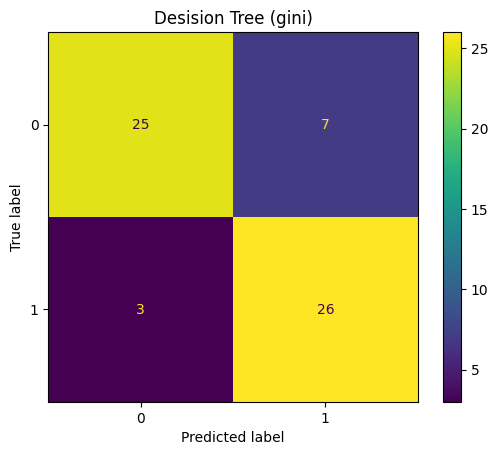

In [154]:
tree_conf_matrix = confusion_matrix(y_test, y_pred_gini)
disp_tree = ConfusionMatrixDisplay(tree_conf_matrix,  display_labels=gini_tree.classes_)
disp_tree.plot()
plt.title("Desision Tree (gini)")
plt.show()

### Logostic Regression

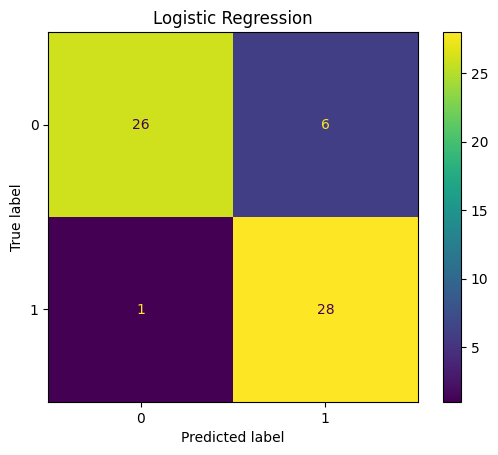

In [158]:
LR_conf_matrix = confusion_matrix(y_test_, y_hat)
disp_tree = ConfusionMatrixDisplay(LR_conf_matrix,  display_labels=gini_tree.classes_)
disp_tree.plot()
plt.title("Logistic Regression")
plt.show()

# Author: Sadra Gholami